# Log-linear model

Logistic regression (softmax regression) on token indicators and on bag of words, evaluated with cross-validation on SST-2 train.

In [1]:
TOKENIZERS = ["nltk", "bpe_500", "bpe_2000", "bpe_8000", "bpe_20000"]  # the first one is the baseline in the comparison
SEEDS = [0]            # one cross-validation run per seed, e.g. [0, 3, 5]
K = 5                  # number of folds
MIN_WORDS = 1          # drop train examples with fewer words (1 keeps all; SST-2 train has many short phrases)
MAX_ITER = 500
ROPE = 0.005  # two systems count as practically equivalent if their mean accuracy differs by less than this
CV = "parents"  # "parents": held-out folds are whole parent sentences (leak-free); "random": plain random folds
SUFFIX = "" if CV == "random" else "_parents"  # appended to the names of the saved results
FEATURES = ["indicator", "bow", "glove"]  # glove: averaged GloVe embeddings, only available with the nltk tokenizer
RECOMPUTE = False  # True: ignore saved results and recompute everything


In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning) 
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

import cv_helpers as cv
from tokenized_data import load

## Cross-validation
For each tokenizer and each representation (token indicators, bag of words): k-fold cross-validation on the train split, repeated for every seed. Accuracies are saved to `results/` for the Bayesian comparison later.

`CV = "parents"` (default): the held-out fold is a random set of whole parent sentences (rows that are not inside a longer row, see `data_analysis.ipynb`). Training uses every other row except those equal to, or inside, a held-out sentence, so the model never sees any part of the text it is tested on. `CV = "random"` gives plain random folds, which leak because sub-phrases of a held-out phrase's sentence are in training.

**Representations.** `indicator` and `bow` are the sparse token features. `glove` is the mean of the GloVe embeddings (6B tokens, 300 dimensions; Pennington, Socher & Manning, 2014) of a sentence's NLTK tokens, standardised with the mean and spread of the training rows. It only exists for the `nltk` tokenizer, because GloVe has vectors for words, not for BPE pieces. Finished runs are reused from `results/` unless `RECOMPUTE = True`.

In [3]:
# raw sentences of the train rows (the same for every tokenizer), used to find the parent sentences
raw_train_text = load("bpe_500")[0]["train"].text.tolist()

def get_folds(y, seed):
    if CV == "parents":
        assert MIN_WORDS == 1, "parent folds use all train rows"
        return cv.parent_folds(raw_train_text, y, K, seed)
    return cv.make_folds(y, K, seed)

results = {}
n_examples = {}

for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    train = splits["train"]
    train = train[train.text.str.split().str.len() >= MIN_WORDS]
    y = train.label.to_numpy()
    print(f"{tok_name}: {len(train)} examples, vocabulary {tokenizer.get_vocab_size()}")
    n_examples[tok_name] = len(train)

    for features in cv.features_for(tok_name, FEATURES):
        name = f"loglinear_{features}_{tok_name}{SUFFIX}"
        info = dict(tokenizer=tok_name, model="loglinear", features=features, seeds=SEEDS, k=K,
                    min_words=MIN_WORDS, cv=CV, max_iter=MAX_ITER)
        accuracies = None if RECOMPUTE else cv.cached_results(name, **info)
        if accuracies is None:
            X, scale = cv.build_features(train, tokenizer, features)
            accuracies = [cv.cv_loglinear(X, y, get_folds(y, seed), MAX_ITER, scale=scale) for seed in SEEDS]
            cv.save_results(name, accuracies, **info)
        else:
            print(f"  {features}: saved results")
        results[(tok_name, features)] = np.array(accuracies)  # shape [seeds, folds]

nltk: 67349 examples, vocabulary 14802
  indicator: saved results
  bow: saved results
  glove: saved results


bpe_500: 67349 examples, vocabulary 500
  indicator: saved results
  bow: saved results


bpe_2000: 67349 examples, vocabulary 2000
  indicator: saved results
  bow: saved results


bpe_8000: 67349 examples, vocabulary 8000
  indicator: saved results
  bow: saved results


bpe_20000: 67349 examples, vocabulary 20000
  indicator: saved results
  bow: saved results


## Results

In [4]:
pd.DataFrame([
    {"tokenizer": t, "features": f, "mean accuracy": a.mean(), "std": a.std(), "scores": a.size}
    for (t, f), a in results.items()
]).round(4)

,tokenizer,features,mean accuracy,std,scores
0,nltk,indicator,0.8089,0.0100,5
1,nltk,bow,0.8083,0.0109,5
2,nltk,glove,0.7866,0.0088,5
3,bpe_500,indicator,0.7134,0.0142,5
4,bpe_500,bow,0.7160,0.0107,5
5,bpe_2000,indicator,0.7741,0.0114,5
6,bpe_2000,bow,0.7715,0.0083,5
7,bpe_8000,indicator,0.8000,0.0111,5
8,bpe_8000,bow,0.7977,0.0080,5
9,bpe_20000,indicator,0.8078,0.0077,5


## Compare tokenizers and representations
Fold accuracies of every system, then pairwise Bayesian comparisons (correlated t-test, as in the tutorial) with a ROPE of `ROPE` accuracy. Folds are identical across systems, so the scores are paired.
`P(A wins)`, `P(tie)` and `P(B wins)` are the posterior probabilities that the true mean difference lies left of, inside, or right of the ROPE.

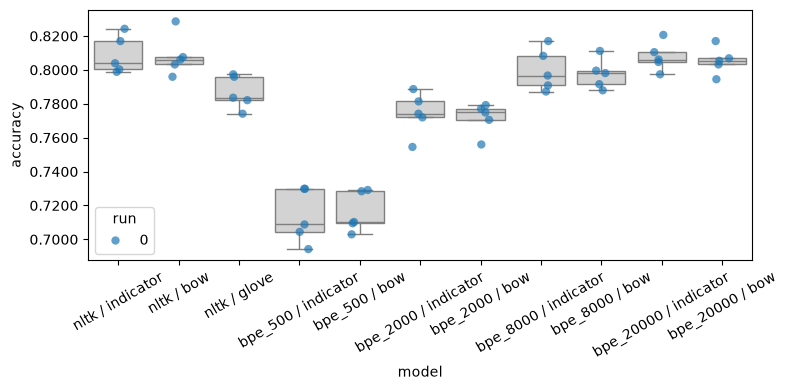

In [5]:
from from_tutorial import analysis

assert len(set(n_examples.values())) == 1, "tokenizers must be evaluated on the same examples"

scores = pd.DataFrame([
    {"model": f"{t} / {f}", "accuracy": acc, "run": run, "fold": fold}
    for (t, f), accs in results.items()
    for run, row in enumerate(accs)
    for fold, acc in enumerate(row)
])
analysis.plot_box_and_points(scores)

In [6]:
def compare(a, b):
    posterior = analysis.BenavoliCorrelatedT(results[a].flatten(), results[b].flatten(), runs=len(SEEDS))
    p_a, p_tie, p_b = posterior.probs(ROPE)
    return {"A": " / ".join(a), "B": " / ".join(b), "mean diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b}

rows = []
# each tokenizer against the baseline tokenizer, per representation
for features in ["indicator", "bow"]:
    for tok_name in TOKENIZERS[1:]:
        rows.append(compare((TOKENIZERS[0], features), (tok_name, features)))
# token indicators against bag of words, per tokenizer
for tok_name in TOKENIZERS:
    rows.append(compare((tok_name, "indicator"), (tok_name, "bow")))

# averaged GloVe embeddings against the sparse representations (NLTK tokens only)
if ("nltk", "glove") in results:
    for features in ["indicator", "bow"]:
        rows.append(compare(("nltk", features), ("nltk", "glove")))

pd.DataFrame(rows).round(3)

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins)
0,nltk / indicator,bpe_500 / indicator,-0.095,1.000,0.000,0.000
1,nltk / indicator,bpe_2000 / indicator,-0.035,0.985,0.009,0.006
2,nltk / indicator,bpe_8000 / indicator,-0.009,0.961,0.038,0.001
3,nltk / indicator,bpe_20000 / indicator,-0.001,0.136,0.800,0.064
4,nltk / bow,bpe_500 / bow,-0.092,1.000,0.000,0.000
5,nltk / bow,bpe_2000 / bow,-0.037,0.976,0.014,0.010
6,nltk / bow,bpe_8000 / bow,-0.011,0.837,0.145,0.018
7,nltk / bow,bpe_20000 / bow,-0.003,0.283,0.678,0.039
8,nltk / indicator,nltk / bow,-0.001,0.201,0.648,0.151
9,bpe_500 / indicator,bpe_500 / bow,0.003,0.028,0.747,0.225


## Evaluation on the validation split
Every system is trained once on all of train and scored once on the SST-2 validation split (whole sentences that never appear in train). This is the most honest estimate of real performance. The table puts it next to the cross-validation scores with random folds and with parent folds; the gap shows how much leakage inflates each cross-validation. Validation accuracies are cached in `results/`.

In [7]:
PREFIX = "loglinear"

def mean_cv(name):
    try:
        return cv.load_results(name).mean()
    except FileNotFoundError:
        return float("nan")

rows = []
for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    train = splits["train"]
    train = train[train.text.str.split().str.len() >= MIN_WORDS]
    validation = splits["validation"]
    y_train, y_val = train.label.to_numpy(), validation.label.to_numpy()

    for features in cv.features_for(tok_name, FEATURES):
        name = f"{PREFIX}_{features}_{tok_name}"
        try:
            validation_accuracy = cv.load_results(name + "_validation").item()   # cached
        except FileNotFoundError:
            X_train, scale = cv.build_features(train, tokenizer, features)
            X_val, _ = cv.build_features(validation, tokenizer, features)
            validation_accuracy = cv.eval_loglinear(X_train, y_train, X_val, y_val, MAX_ITER, scale=scale)
            cv.save_results(name + "_validation", [[validation_accuracy]], tokenizer=tok_name, model=PREFIX,
                            features=features, min_words=MIN_WORDS, max_iter=MAX_ITER)
        rows.append({
            "tokenizer": tok_name, "features": features,
            "cv random folds": mean_cv(name),
            "cv parent folds": mean_cv(name + "_parents"),
            "validation": validation_accuracy,
        })

table = pd.DataFrame(rows)
table["gap random"] = table["cv random folds"] - table["validation"]
table["gap parents"] = table["cv parent folds"] - table["validation"]
print(f"majority-class baseline on validation: {max(y_val.mean(), 1 - y_val.mean()):.4f}")
table.round(4)

majority-class baseline on validation: 0.5092


,tokenizer,features,cv random folds,cv parent folds,validation,gap random,gap parents
0,nltk,indicator,0.9008,0.8089,0.8142,0.0865,-0.0054
1,nltk,bow,0.9005,0.8083,0.8085,0.0920,-0.0002
2,nltk,glove,NaN,0.7866,0.7810,NaN,0.0057
3,bpe_500,indicator,0.7376,0.7134,0.7489,-0.0113,-0.0354
4,bpe_500,bow,0.7403,0.7160,0.7339,0.0063,-0.0179
5,bpe_2000,indicator,0.8295,0.7741,0.7798,0.0496,-0.0057
6,bpe_2000,bow,0.8298,0.7715,0.7867,0.0431,-0.0152
7,bpe_8000,indicator,0.8925,0.8000,0.8154,0.0771,-0.0154
8,bpe_8000,bow,0.8919,0.7977,0.8188,0.0731,-0.0211
9,bpe_20000,indicator,0.9014,0.8078,0.8268,0.0746,-0.0190
